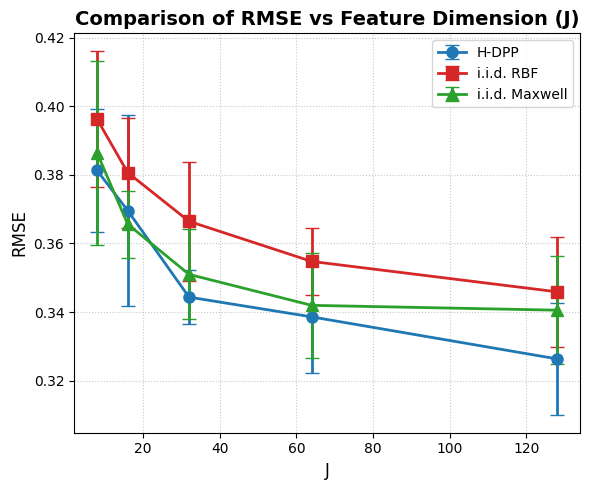

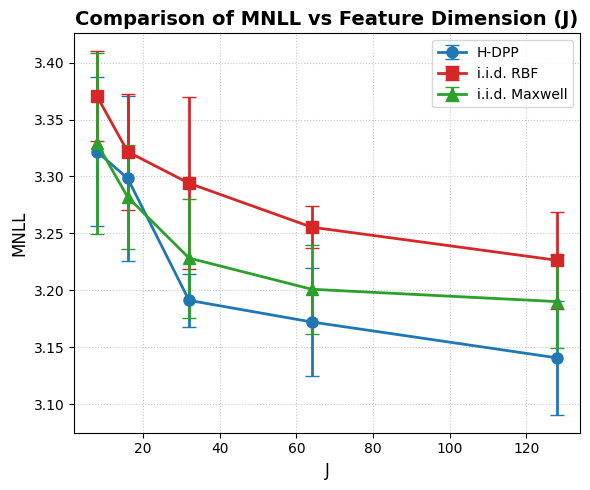


J     | Model      | RMSE (Mean ± Std)         | NLL (Mean ± Std)         
--------------------------------------------------------------------------------------------------------------
8     | H-DPP      | 0.381285 ± 0.017877 | 3.321787 ± 0.065518
8     | i.i.d. RBF | 0.396245 ± 0.019691 | 3.370385 ± 0.039340
8     | i.i.d. Maxwell | 0.386442 ± 0.026793 | 3.329078 ± 0.079488
--------------------------------------------------------------------------------------------------------------
16    | H-DPP      | 0.369584 ± 0.027812 | 3.298298 ± 0.072658
16    | i.i.d. RBF | 0.380657 ± 0.016042 | 3.321746 ± 0.050957
16    | i.i.d. Maxwell | 0.365619 ± 0.009713 | 3.281927 ± 0.045715
--------------------------------------------------------------------------------------------------------------
32    | H-DPP      | 0.344370 ± 0.007799 | 3.191262 ± 0.023522
32    | i.i.d. RBF | 0.366451 ± 0.017278 | 3.294046 ± 0.075584
32    | i.i.d. Maxwell | 0.350997 ± 0.013114 | 3.228401 ± 0.052269
------------

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

def load_summary_data(J_values, seeds, base_dir='.'):
    """
    Load data from files with format: concrete_{model}_loss_{J}_{seed}.txt
    File structure: Line 1 = RMSE, Line 2 = NLL

    Returns:
    - dict: Structured results containing means and stds for each J
    """
    models = ['orf', 'rbf', 'maxwell']
    # Initialize storage for all J values
    summary = {
        'J': [],
        'orf_rmse': [], 'orf_nll': [],
        'rbf_rmse': [], 'rbf_nll': [],
        'maxwell_rmse': [], 'maxwell_nll': []
    }

    for J in J_values:
        j_data = {m: {'rmse': [], 'nll': []} for m in models}
        valid_j = True

        for seed in seeds:
            for model in models:
                file_path = f"{base_dir}/concrete_{model}_loss_{J}_{seed}.txt"

                if os.path.exists(file_path):
                    try:
                        # Read the two lines: [0] is RMSE, [1] is NLL
                        data = np.loadtxt(file_path)
                        if data.size == 2:
                            j_data[model]['rmse'].append(data[0])
                            j_data[model]['nll'].append(data[1])
                        else:
                            print(f"Warning: Unexpected data format in {file_path}")
                    except Exception as e:
                        print(f"Error reading {file_path}: {e}")
                else:
                    print(f"Missing: {file_path}")
                    valid_j = False

        if valid_j:
            summary['J'].append(J)
            for m in models:
                summary[f'{m}_rmse'].append(j_data[m]['rmse'])
                summary[f'{m}_nll'].append(j_data[m]['nll'])

    return summary

def plot_performance_vs_J(summary):
    """
    Plot Mean ± Std Dev for RMSE and NLL across different J values
    """
    J_vals = summary['J']
    models = [('orf', 'H-DPP', '#1f77b4', 'o'),
              ('rbf', 'i.i.d. RBF', '#d62728', 's'),
              ('maxwell', 'i.i.d. Maxwell', '#2ca02c', '^')]

    metrics = [('rmse', 'RMSE'), ('nll', 'MNLL')]

    for metric_key, metric_name in metrics:
        # Create a new, independent figure for the current metric
        fig, ax = plt.subplots(figsize=(6, 5))

        for m_key, m_label, m_color, m_marker in models:
            # Calculate mean and std across seeds for each J
            data_list = summary[f'{m_key}_{metric_key}']
            means = [np.mean(seeds_val) for seeds_val in data_list]
            stds = [np.std(seeds_val) for seeds_val in data_list]

            # Plot error bars for the current model
            ax.errorbar(J_vals, means, yerr=stds, label=m_label, color=m_color,
                        marker=m_marker, capsize=5, lw=2, markersize=8)

        # Decorate the plot
        ax.set_title(f'Comparison of {metric_name} vs Feature Dimension (J)', fontsize=14, fontweight='bold')
        ax.set_xlabel('J', fontsize=12)
        ax.set_ylabel(metric_name, fontsize=12)
        ax.grid(True, linestyle=':', alpha=0.7)
        ax.legend()

        # Adjust layout and save/show the figure independently
        plt.tight_layout()
        plt.savefig(f'{metric_name}.png')
        plt.show()

def print_stat_table(summary):
    """
    Print a formatted table showing the metrics for each model and J
    """
    print("\n" + "="*110)
    print(f"{'J':<5} | {'Model':<10} | {'RMSE (Mean ± Std)':<25} | {'NLL (Mean ± Std)':<25}")
    print("-" * 110)

    models = [('orf', 'H-DPP'), ('rbf', 'i.i.d. RBF'), ('maxwell', 'i.i.d. Maxwell')]

    for i, J in enumerate(summary['J']):
        for m_key, m_label in models:
            rmse_vals = summary[f'{m_key}_rmse'][i]
            nll_vals = summary[f'{m_key}_nll'][i]

            rmse_m, rmse_s = np.mean(rmse_vals), np.std(rmse_vals)
            nll_m, nll_s = np.mean(nll_vals), np.std(nll_vals)

            print(f"{J:<5} | {m_label:<10} | {rmse_m:.6f} ± {rmse_s:.6f} | {nll_m:.6f} ± {nll_s:.6f}")
        print("-" * 110)

# ==================== Execution Configuration ====================
# Define your J values and seeds
target_J = [8, 16, 32, 64, 128]
target_seeds = [1, 5, 12, 14, 16]  # Adjust based on your actual filenames
data_dir = '.'  # Current directory

# 1. Load data
res_summary = load_summary_data(target_J, target_seeds, data_dir)

# 2. Visualization
if res_summary['J']:
    plot_performance_vs_J(res_summary)
    # 3. Text Statistics
    print_stat_table(res_summary)
else:
    print("No valid data files found. Please check file paths and naming.")